# PA2 · Question 2 · Step 2: Figure 1 (how do the training digits move?)

**Today's goal (about 45–60 minutes).**

1. Measure the motion of the digits in the **first 50 training videos** with optical flow.
2. Write **two small functions** (✏️ YOUR TURN): `keep_mask` and `direction_deg`. Each one has an automatic check.
3. Draw **Figure 1**: (a) a histogram of motion **direction**, (b) a histogram of motion **speed**.

**Why this matters.** Q2.1 asks: *would mirrored or rotated videos already look familiar to a model trained on this data?* That depends on which directions and speeds appear in training, and this figure shows exactly that.

**Kaggle settings:** Internet **On** (for the data download), Accelerator **None** (no GPU needed).

In [1]:
import os, glob
import numpy as np
import torch, torchvision
import matplotlib.pyplot as plt
try:
    import cv2
except ImportError:
    raise ImportError("OpenCV is missing. Run  !pip install opencv-python-headless  in a cell, then run this cell again.")
print("OpenCV", cv2.__version__, "| torch", torch.__version__)

OpenCV 4.14.0 | torch 2.11.0+cu128


## 1. Load the data (same code as Step 1)

In [2]:
ON_KAGGLE = os.path.exists("/kaggle/input")
DATA_ROOT = "/tmp/mmnist" if ON_KAGGLE else "./data"
found = glob.glob("/kaggle/input/**/mnist_test_seq.npy", recursive=True) if ON_KAGGLE else []
if found:
    os.makedirs(os.path.join(DATA_ROOT, "MovingMNIST"), exist_ok=True)
    link = os.path.join(DATA_ROOT, "MovingMNIST", "mnist_test_seq.npy")
    if not os.path.exists(link):
        os.symlink(found[0], link)

ds = torchvision.datasets.MovingMNIST(root=DATA_ROOT, split=None, download=True)
videos_u8 = ds.data if hasattr(ds, "data") else torch.stack([ds[i] for i in range(len(ds))])
assert tuple(videos_u8.shape) == (10000, 20, 1, 64, 64)
train_u8 = videos_u8[0:8000]

def to_float(v_u8):
    return v_u8.float() / 255.0

# The handout says: compute flow on frames converted to uint8 (multiply the [0,1] frames by 255).
# That gives back exactly the original uint8 data, as this check shows, so we can use train_u8 directly.
assert torch.equal((to_float(train_u8[:2]) * 255).round().to(torch.uint8), train_u8[:2])
print("data ready:", tuple(train_u8.shape))

100%|██████████| 819M/819M [00:34<00:00, 23.6MB/s]


data ready: (8000, 20, 1, 64, 64)


## 2. Background: what optical flow measures

For **every pixel**, optical flow answers: *"this small piece of the image: where did it move in the next frame?"*
The answer is a small arrow (a displacement) with two parts:

| Part | Direction | Positive means |
|---|---|---|
| $d_x$ | along the **columns** | moving **right** |
| $d_y$ | along the **rows** | moving **down** (rows are numbered from the top, so they increase downward) |

**Farneback's method** is a classic algorithm for this. It describes each small neighbourhood of the image with a simple polynomial surface and finds the shift that best matches the next frame. Here it is only a **measuring tool**, and the handout fixes its settings exactly:

`cv2.calcOpticalFlowFarneback(prev, next, None, 0.5, 3, 15, 3, 5, 1.2, 0)`

| Value | Meaning |
|---|---|
| 0.5, 3 | build an image pyramid: each level is half the size, 3 levels (this helps catch larger motions) |
| 15 | averaging window size (pixels) |
| 3 | iterations per pyramid level |
| 5, 1.2 | neighbourhood size and smoothing of the polynomial fit |
| 0 | no special flags |

**Why we filter pixels.** Most of the image is black background. Flow there is meaningless, because there is nothing to track. So we keep a pixel only if

1. it is **bright in both frames** (intensity > 0.2 on the [0, 1] scale, which means **> 51 on the uint8 scale**), so it sits on a digit, **and**
2. it **really moved**: flow magnitude $\sqrt{d_x^2 + d_y^2} > 0.5$ pixels.

This cell is provided:

In [3]:
def flow_for_pair(prev_u8, next_u8):
    # prev_u8, next_u8: (64, 64) uint8 numpy arrays (two consecutive frames).
    # Returns dx, dy: (64, 64) float arrays, one displacement per pixel.
    prev_u8 = np.ascontiguousarray(prev_u8)
    next_u8 = np.ascontiguousarray(next_u8)
    flow = cv2.calcOpticalFlowFarneback(prev_u8, next_u8, None, 0.5, 3, 15, 3, 5, 1.2, 0)
    dx = flow[..., 0].astype(np.float64)   # along columns: positive = moving RIGHT
    dy = flow[..., 1].astype(np.float64)   # along rows:    positive = moving DOWN
    return dx, dy

## 3. ✏️ YOUR TURN (1): `keep_mask`

Return a **True/False array** (same shape as the frames): True for pixels we keep.

A pixel is kept only if **all three** are true:
* `prev_u8 > 51` (bright in the first frame),
* `next_u8 > 51` (bright in the second frame, at the **same** location),
* magnitude $\sqrt{d_x^2 + d_y^2} > 0.5$.

**Hints**
* Comparisons on numpy arrays work **pixel by pixel**: `prev_u8 > 51` gives a True/False array.
* To combine True/False arrays, use `&` (and). Put brackets around each comparison: `(a > 1) & (b > 2)`.
* `np.sqrt(dx**2 + dy**2)` gives the magnitude of every arrow.
* Careful: the rule is **strictly greater** (`>`), not `>=`. The check below tests exactly this.

In [4]:
def keep_mask(prev_u8, next_u8, dx, dy):
    bright_prev = prev_u8 > 51                       # Rule 1
    bright_next = next_u8 > 51                       # Rule 2 (same test, other frame)
    moved       = np.sqrt(dx**2 + dy**2) > 0.5       # Rule 3 (length, then compare)
    return bright_prev & bright_next & moved


# ---------- automatic check (do not edit) ----------
_prev = np.array([[ 52,  52,  51, 200, 200]], dtype=np.uint8)
_next = np.array([[ 52,  30, 200, 200, 200]], dtype=np.uint8)
_dx   = np.array([[0.6, 1.0, 1.0, 0.5, 0.0]])
_dy   = np.array([[0.0, 0.0, 0.0, 0.0, -2.0]])
_expected = np.array([[True, False, False, False, True]])
#  column 1: bright in both, moved 0.6   -> keep
#  column 2: dark in the next frame      -> drop
#  column 3: 51 is NOT > 51              -> drop
#  column 4: moved exactly 0.5 (not > 0.5) -> drop
#  column 5: moved 2 px straight up      -> keep
try:
    _got = np.asarray(keep_mask(_prev, _next, _dx, _dy))
    print("expected:", _expected.tolist())
    print("yours:   ", _got.tolist())
    print("OK: keep_mask is correct." if np.array_equal(_got, _expected)
          else "FIX: compare the columns above with the comments in this cell.")
except NotImplementedError:
    print("keep_mask not written yet.")

expected: [[True, False, False, False, True]]
yours:    [[True, False, False, False, True]]
OK: keep_mask is correct.


## 4. ✏️ YOUR TURN (2): `direction_deg`

The handout defines the direction of an arrow as

$$\theta = \operatorname{atan2}(-d_y,\ d_x)\quad\text{in degrees, on } [0^\circ, 360^\circ).$$

**Why the minus sign?** On screen, $d_y$ is positive when moving **down**. In normal maths, "up" is positive.
Using $-d_y$ makes the angle read like a normal compass of maths:

| Motion on screen | $(d_x, d_y)$ | $\theta$ |
|---|---|---|
| right | (1, 0) | 0° |
| up | (0, −1) | 90° |
| left | (−1, 0) | 180° |
| down | (0, 1) | 270° |

**Three steps:**
1. `np.arctan2(Y, X)` gives the angle in **radians**. Careful: the **vertical part comes first**. Here the vertical part is `-dy` and the horizontal part is `dx`.
2. `np.degrees(...)` converts to degrees. The result lies between −180° and 180°.
3. Negative angles must move into [0°, 360°): for example −90° becomes 270°. The operation `% 360` does exactly this.

In [5]:
def direction_deg(dx, dy):
    angle_rad = np.arctan2(-dy, dx)                  # vertical part first
    angle_deg = angle_rad * 180 / np.pi              # radians -> degrees
    return angle_deg % 360                           # into [0, 360)


# ---------- automatic check (do not edit) ----------
_tests = {"right": (1, 0, 0.0), "up": (0, -1, 90.0), "left": (-1, 0, 180.0),
          "down": (0, 1, 270.0), "up-left": (-1, -1, 135.0), "down-right": (1, 1, 315.0)}
try:
    _all_ok = True
    for name, (ddx, ddy, want) in _tests.items():
        got = float(np.asarray(direction_deg(np.array([float(ddx)]), np.array([float(ddy)])))[0])
        ok = abs(got - want) < 1e-9
        _all_ok &= ok
        print(f"{name:<10} (dx={ddx:>2}, dy={ddy:>2})  expected {want:6.1f}°   yours {got:8.3f}°   {'OK' if ok else 'FIX'}")
    print("\nOK: direction_deg is correct." if _all_ok else "\nFIX: check the order inside np.arctan2, the minus sign, and % 360.")
except NotImplementedError:
    print("direction_deg not written yet.")

right      (dx= 1, dy= 0)  expected    0.0°   yours    0.000°   OK
up         (dx= 0, dy=-1)  expected   90.0°   yours   90.000°   OK
left       (dx=-1, dy= 0)  expected  180.0°   yours  180.000°   OK
down       (dx= 0, dy= 1)  expected  270.0°   yours  270.000°   OK
up-left    (dx=-1, dy=-1)  expected  135.0°   yours  135.000°   OK
down-right (dx= 1, dy= 1)  expected  315.0°   yours  315.000°   OK

OK: direction_deg is correct.


## 5. Measure all 950 frame pairs (provided; just run)

For each of the first 50 training videos and each consecutive pair of frames $(x_s, x_{s+1})$, $s = 1, \dots, 19$:
compute the flow, keep the good pixels, and pool everything together. This takes about a minute on a CPU.

Remember the numbering: tensor index `s` holds frame number `s + 1`, so the pair `(s, s+1)` with `s = 0..18` covers frame pairs (1, 2) … (19, 20).

In [6]:
N_VIDEOS = 50
frames_np = train_u8[:N_VIDEOS, :, 0].numpy()        # (50, 20, 64, 64) uint8

kept_dx, kept_dy = [], []
n_pairs = 0
for v in range(N_VIDEOS):
    for s in range(19):                               # tensor indices 0..18  ->  frame pairs (1,2) ... (19,20)
        prev, nxt = frames_np[v, s], frames_np[v, s + 1]
        dx, dy = flow_for_pair(prev, nxt)
        keep = keep_mask(prev, nxt, dx, dy)
        kept_dx.append(dx[keep])
        kept_dy.append(dy[keep])
        n_pairs += 1

dx_all = np.concatenate(kept_dx)
dy_all = np.concatenate(kept_dy)
theta  = direction_deg(dx_all, dy_all)               # degrees in [0, 360)
speed  = np.sqrt(dx_all**2 + dy_all**2)              # pixels per frame
median_speed = float(np.median(speed))

print(f"frame pairs used : {n_pairs}   (must be 950)")
print(f"pixels kept      : {len(speed):,}")
print(f"median speed     : {median_speed:.3g} pixels per frame")

frame pairs used : 950   (must be 950)
pixels kept      : 103,050
median speed     : 3.32 pixels per frame


## 6. Draw Figure 1 (provided; just run)

What the handout asks for, and how this cell does it:

* **Fractions, not counts.** Each kept pixel gets weight $1/N$, so the bars add up to 1.
* **(a) Direction:** 18 bins of 20° on [0°, 360°), plus a horizontal line at $1/18 \approx 0.056$. That line is the height every bar would have if all directions were **equally common** (a perfectly uniform distribution).
* **(b) Speed:** histogram of $\sqrt{d_x^2 + d_y^2}$, with the **median** marked by a vertical line.
* The figure is saved as `figure1.png` (on Kaggle it appears in the *Output* panel), and a draft caption is printed for your report.

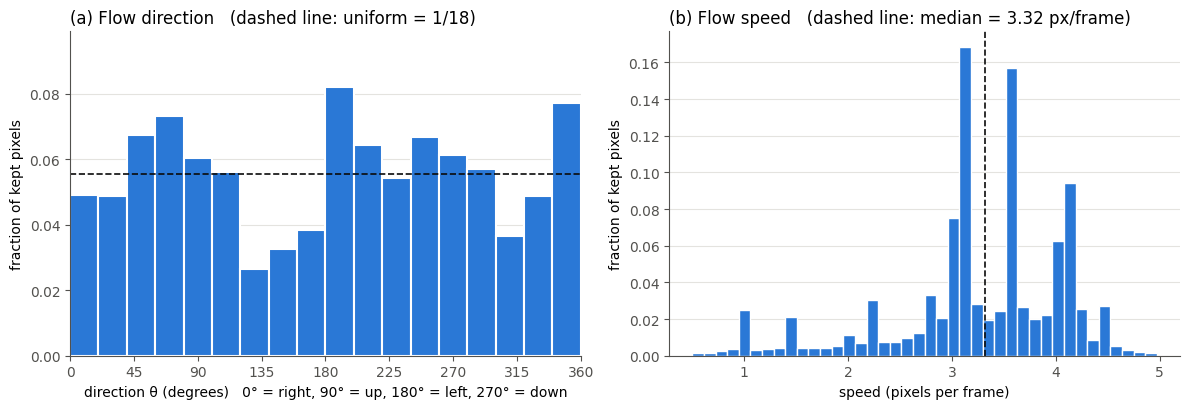

Draft caption:
Figure 1. Dense optical flow (OpenCV Farneback) on the first 50 training videos, 950 consecutive frame pairs; pixels kept if brighter than 0.2 in both frames and flow magnitude > 0.5 px. (a) Direction θ = atan2(−dy, dx), 18 bins of 20°, dashed line = 1/18 (uniform). (b) Speed, dashed line = median (3.32 px/frame). N = 103,050 pixels kept. Bars show fractions of kept pixels.
(Speeds above the 99.5th percentile are outside the plotted range of (b); they are still counted in N and the median.)


In [7]:
BAR = "#2a78d6"; INK = "#0b0b0b"; INK2 = "#52514e"; GRID = "#e4e3df"
N = len(speed)
w = np.full(N, 1.0 / N)                                # weights -> fractions

fig, (axA, axB) = plt.subplots(1, 2, figsize=(12, 4.2))

# (a) direction
axA.hist(theta, bins=np.arange(0, 361, 20), weights=w, color=BAR, edgecolor="white", linewidth=1.5)
axA.axhline(1/18, color=INK, linestyle="--", linewidth=1.2)
axA.set_xlim(0, 360); axA.set_xticks(np.arange(0, 361, 45))
axA.set_ylim(0, max(axA.get_ylim()[1], 1/18) * 1.15)
axA.set_xlabel("direction θ (degrees)   0° = right, 90° = up, 180° = left, 270° = down")
axA.set_ylabel("fraction of kept pixels")
axA.set_title("(a) Flow direction   (dashed line: uniform = 1/18)", loc="left")

# (b) speed
top = np.percentile(speed, 99.5)
axB.hist(speed, bins=np.linspace(0.5, top, 41), weights=w, color=BAR, edgecolor="white", linewidth=1.0)
axB.axvline(median_speed, color=INK, linestyle="--", linewidth=1.2)
axB.set_xlabel("speed (pixels per frame)")
axB.set_ylabel("fraction of kept pixels")
axB.set_title(f"(b) Flow speed   (dashed line: median = {median_speed:.3g} px/frame)", loc="left")

for ax in (axA, axB):
    ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=INK2); ax.spines["left"].set_color(INK2); ax.spines["bottom"].set_color(INK2)

plt.tight_layout()
fig.savefig("figure1.png", dpi=200, bbox_inches="tight")
plt.show()

print("Draft caption:")
print(f"Figure 1. Dense optical flow (OpenCV Farneback) on the first 50 training videos, "
      f"{n_pairs} consecutive frame pairs; pixels kept if brighter than 0.2 in both frames and "
      f"flow magnitude > 0.5 px. (a) Direction θ = atan2(−dy, dx), 18 bins of 20°, dashed line = 1/18 (uniform). "
      f"(b) Speed, dashed line = median ({median_speed:.3g} px/frame). "
      f"N = {N:,} pixels kept. Bars show fractions of kept pixels.")
print("(Speeds above the 99.5th percentile are outside the plotted range of (b); they are still counted in N and the median.)")

## 7. Sanity checks (just run)

In [8]:
frac_a, _ = np.histogram(theta, bins=np.arange(0, 361, 20))
checks = {
    "950 frame pairs used":            n_pairs == 950,
    "all angles in [0, 360)":          bool(np.all((theta >= 0) & (theta < 360))),
    "all kept speeds > 0.5":           bool(np.all(speed > 0.5)),
    "direction fractions sum to 1":    abs(frac_a.sum() / N - 1) < 1e-9,
}
for name, ok in checks.items():
    print(f"{'OK ' if ok else 'FIX'}  {name}")

OK   950 frame pairs used
OK   all angles in [0, 360)
OK   all kept speeds > 0.5
OK   direction fractions sum to 1


## 8. (Optional) Thinking tool for Q2.1

Q2.1's hint asks: *how would the direction histogram change if every training video were mirrored? Or rotated by 90°?*

* **Mirror** flips left and right, so $d_x \to -d_x$ while $d_y$ stays. The angle changes as $\theta \to 180^\circ - \theta$.
* **Rotation by 90° anticlockwise** turns every arrow by 90°, so $\theta \to \theta + 90^\circ$.

(Try it with one arrow: "right" (0°) mirrored is "left" (180°); "right" rotated is "up" (90°).)

The cell below draws the histogram your data **would** have after each change, next to the real one. **You** must interpret it:
are the three shapes similar? What does that say about whether mirrored and rotated motion is *familiar* to the model?
(The y-axis starts at 0 on purpose, so that small random wiggles are not blown up into big-looking differences.)

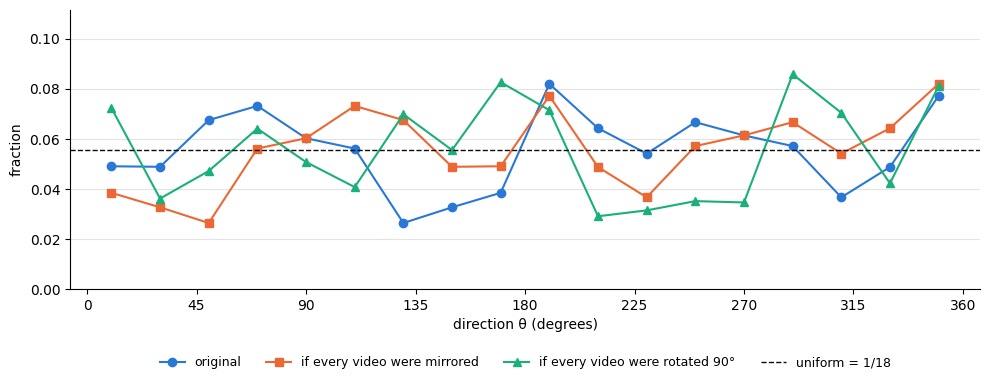

In [9]:
bins = np.arange(0, 361, 20)
centres = bins[:-1] + 10
hist = lambda th: np.histogram(th % 360, bins=bins)[0] / len(th)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(centres, hist(theta),         marker="o", color="#2a78d6", label="original")
ax.plot(centres, hist(180 - theta),   marker="s", color="#eb6834", label="if every video were mirrored")
ax.plot(centres, hist(theta + 90),    marker="^", color="#1baf7a", label="if every video were rotated 90°")
ax.axhline(1/18, color="#0b0b0b", linestyle="--", linewidth=1, label="uniform = 1/18")
ax.set_xticks(np.arange(0, 361, 45)); ax.set_xlabel("direction θ (degrees)"); ax.set_ylabel("fraction")
ax.set_ylim(0, max(hist(theta).max(), hist(180 - theta).max(), hist(theta + 90).max()) * 1.3)  # start at 0: honest scale
ax.legend(frameon=False, fontsize=9, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.grid(axis="y", color="#e4e3df"); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

## 9. When you are done

1. Click **Save Version**. Download `figure1.png` from the Output panel for your report.
2. Write down the **median speed** and **N**: they go in the caption. Q2.1 also asks what **2× and 3×** speed mean in pixels per frame (think: what happens to the distance moved between the frames the model sees?).
3. **Q2.1 also asks:** optical flow is unreliable where digits **overlap**. Could that bias these histograms enough to change your answer? Write your own thoughts before we discuss it.
4. Add today's prompts to your `ai_log.md`.
5. **Next step:** build **model A** (the ConvLSTM) and check its parameter count (480,784).